# Sales Prediction Using Python

## Project Objective

The objective of this project is to build a regression model that predicts product sales based on advertising spend across different media channels (TV, Radio, Newspaper).


## 1. Import Required Libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 2. Load and Clean the Advertising Dataset


In [4]:
df = pd.read_csv("Advertising.csv")

In [5]:
# Remove the extra index column if it is present.
df = df.drop(columns=["Unnamed: 0"], errors="ignore")

# Standardize column names for consistent use in the notebook.
df.columns = df.columns.str.strip()
df = df.rename(columns={
    "radio": "Radio",
    "newspaper": "Newspaper",
    "sales": "Sales"
})

print(df.columns.tolist())

['TV', 'Radio', 'Newspaper', 'Sales']


In [6]:
df.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


## 3. Exploratory Data Analysis (EDA)



In [7]:
df.shape

(200, 4)

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


In [9]:
df.isnull().sum()

TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

In [10]:
df.describe()

,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14.022500
std,85.854236,14.846809,21.778621,5.217457
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,10.375000
50%,149.750000,22.900000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000


In [11]:
df.columns

Index(['TV', 'Radio', 'Newspaper', 'Sales'], dtype='str')

## 4. Data Visualization

### 4.1 Pairplot

A pairplot is used to visualize relationships between all numerical features
and sales in the dataset.

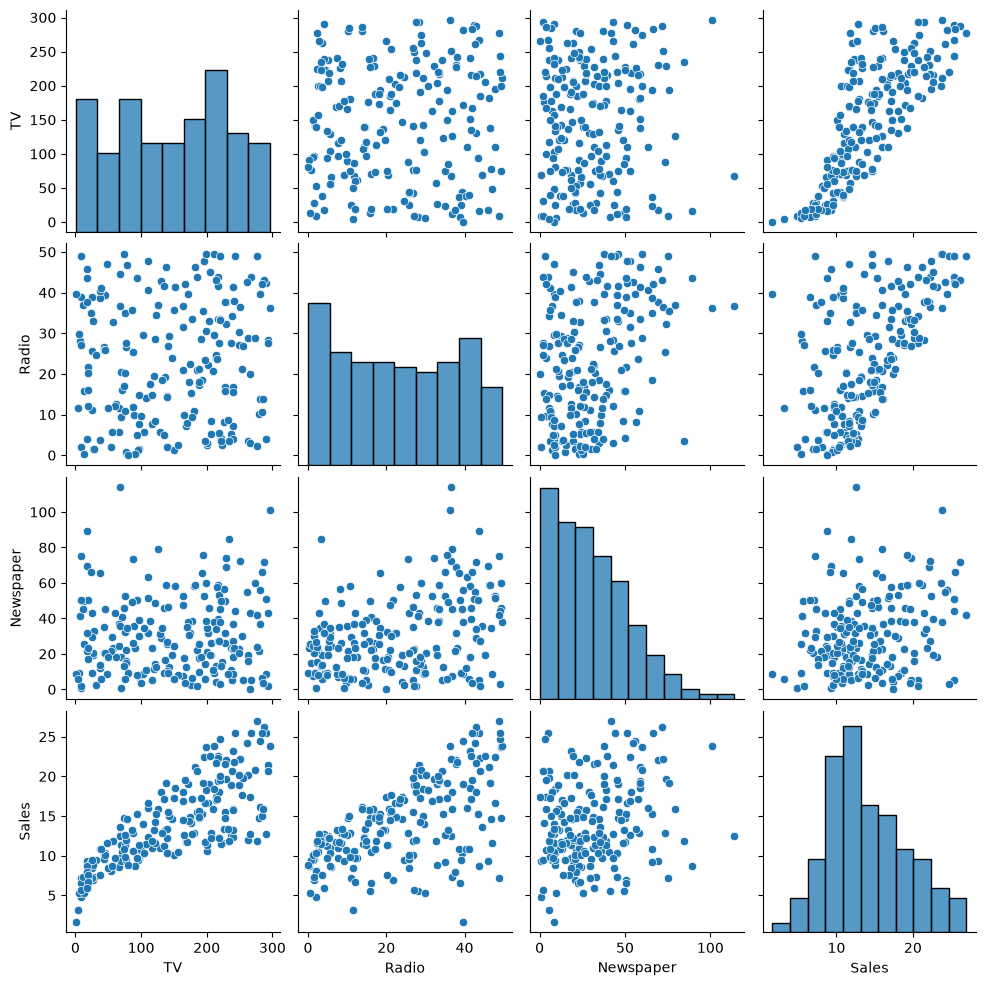

In [12]:
sns.pairplot(df)
plt.show()

### 4.2 Individual Scatter Plots

Scatter plots show how each advertising channel is associated with Sales. Advertising expenditure is shown on the x-axis and Sales on the y-axis.

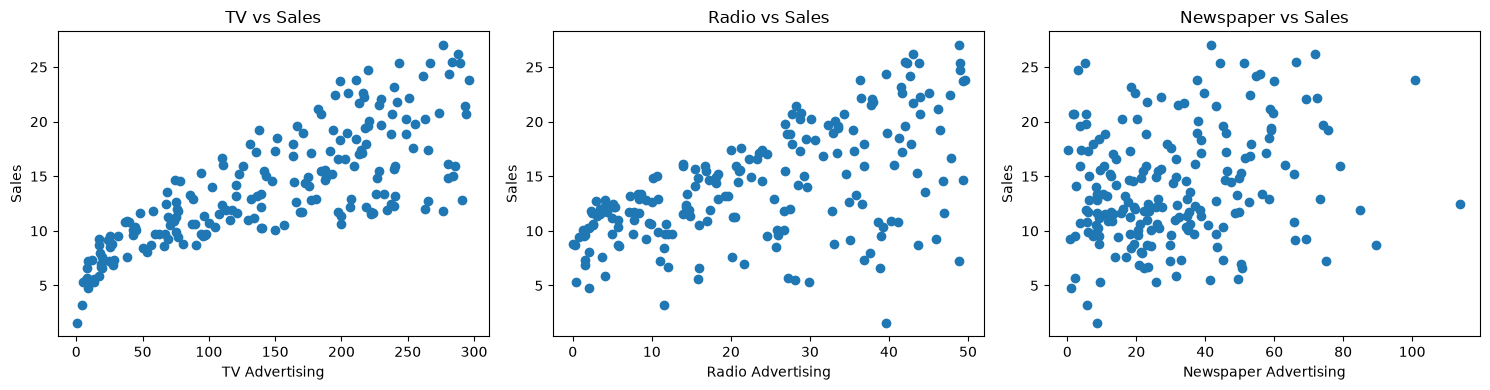

In [13]:
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.scatter(df["TV"], df["Sales"])
plt.xlabel("TV Advertising")
plt.ylabel("Sales")
plt.title("TV vs Sales")

plt.subplot(1, 3, 2)
plt.scatter(df["Radio"], df["Sales"])
plt.xlabel("Radio Advertising")
plt.ylabel("Sales")
plt.title("Radio vs Sales")

plt.subplot(1, 3, 3)
plt.scatter(df["Newspaper"], df["Sales"])
plt.xlabel("Newspaper Advertising")
plt.ylabel("Sales")
plt.title("Newspaper vs Sales")

plt.tight_layout()
plt.show()

### 4.3 Correlation Matrix


In [14]:
correlation_matrix = df.corr()

correlation_matrix

,TV,Radio,Newspaper,Sales
TV,1.000000,0.054809,0.056648,0.782224
Radio,0.054809,1.000000,0.354104,0.576223
Newspaper,0.056648,0.354104,1.000000,0.228299
Sales,0.782224,0.576223,0.228299,1.000000


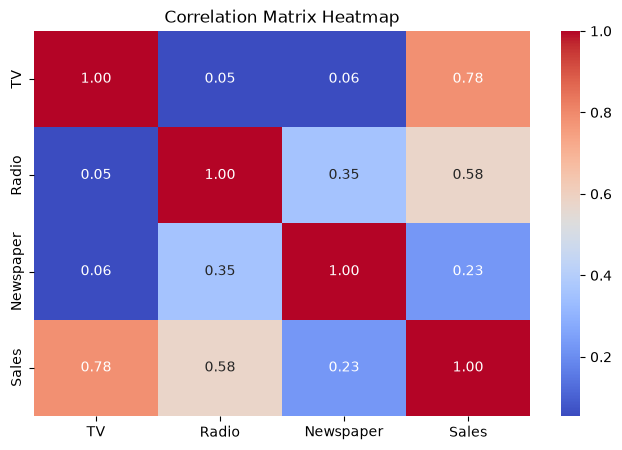

In [15]:
plt.figure(figsize=(8, 5))

sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Matrix Heatmap")
plt.show()

### Heatmap Observation

TV advertising has the highest correlation with Sales (0.78),
followed by Radio (0.58) and Newspaper (0.23).

This indicates that TV advertising has the strongest linear
relationship with Sales in this dataset.

## 5. Prepare Data for Machine Learning

### 5.1 Separate Features and Target

`X` stores TV, Radio, and Newspaper advertising expenditure. `y` stores the Sales values the model will learn to predict.

In [16]:
# Input features: advertising expenditure on each channel.
X = df[["TV", "Radio", "Newspaper"]]

# Target: product sales.
y = df["Sales"]

### 5.2 Train/Test Split

We split the dataset into 80% training data and 20% testing data. The model learns from the training data, while the test data is held back to evaluate predictions on unseen records. `random_state=42` makes the split reproducible.

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [18]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (160, 3)
X_test: (40, 3)
y_train: (160,)
y_test: (40,)


## 6. Model Training

### 6.1 Linear Regression

Linear Regression is used to predict product sales based on
advertising expenditure on TV, Radio, and Newspaper.

In [19]:
linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[0.04,0.19,0. ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['TV','Radio','Newspaper']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.979
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


In [20]:
y_pred_lr = linear_model.predict(X_test)

In [21]:
comparison = pd.DataFrame({
    "Actual Sales": y_test.values,
    "Predicted Sales": y_pred_lr
})

comparison.head()

,Actual Sales,Predicted Sales
0,16.9,16.408024
1,22.4,20.889882
2,21.4,21.553843
3,7.3,10.608503
4,24.7,22.112373


### 6.2 Random Forest Regressor



In [22]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [23]:
y_pred_rf = rf_model.predict(X_test)

rf_comparison = pd.DataFrame({
    "Actual Sales": y_test.values,
    "Predicted Sales": y_pred_rf
})

rf_comparison.head()

,Actual Sales,Predicted Sales
0,16.9,17.698
1,22.4,21.804
2,21.4,20.619
3,7.3,6.793
4,24.7,22.927


## 7. Model Evaluation

Evaluating both regression models using MAE, RMSE, and R-squared score.

In [24]:
# Linear Regression evaluation

lr_mae = mean_absolute_error(y_test, y_pred_lr)
lr_rmse = np.sqrt(mean_squared_error(y_test, y_pred_lr))
lr_r2 = r2_score(y_test, y_pred_lr)


# Random Forest evaluation

rf_mae = mean_absolute_error(y_test, y_pred_rf)
rf_rmse = np.sqrt(mean_squared_error(y_test, y_pred_rf))
rf_r2 = r2_score(y_test, y_pred_rf)


# Compare both models

model_comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [lr_mae, rf_mae],
    "RMSE": [lr_rmse, rf_rmse],
    "R2 Score": [lr_r2, rf_r2]
})

model_comparison

,Model,MAE,RMSE,R2 Score
0,Linear Regression,1.460757,1.781600,0.899438
1,Random Forest,0.620325,0.768717,0.981278


## 8. Residual Analysis

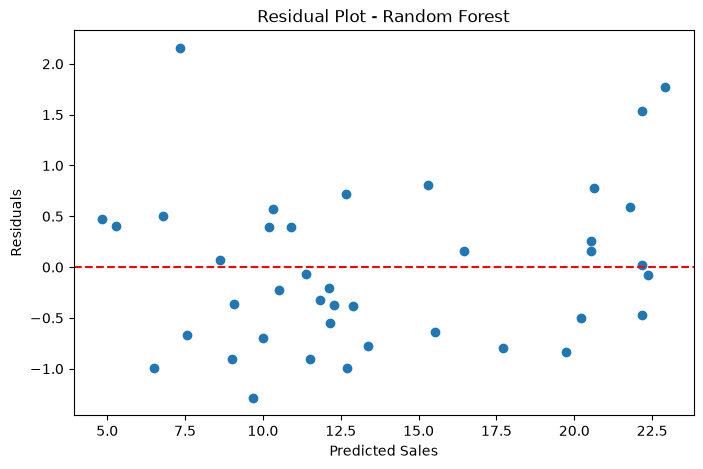

In [25]:
residuals = y_test - y_pred_rf

plt.figure(figsize=(8, 5))

plt.scatter(y_pred_rf, residuals)

plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Sales")
plt.ylabel("Residuals")
plt.title("Residual Plot - Random Forest")

plt.show()

### Residual Plot Observation

The residuals are mostly scattered around the zero line, with both positive and negative values. There is no strong obvious curved pattern in this plot, although a few observations have larger errors and the spread is not perfectly uniform. This suggests the model's errors are reasonably distributed, but they are not all the same size.

## 9. Feature Importance



In [26]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance

,Feature,Importance
0,TV,0.624810
1,Radio,0.362214
2,Newspaper,0.012976


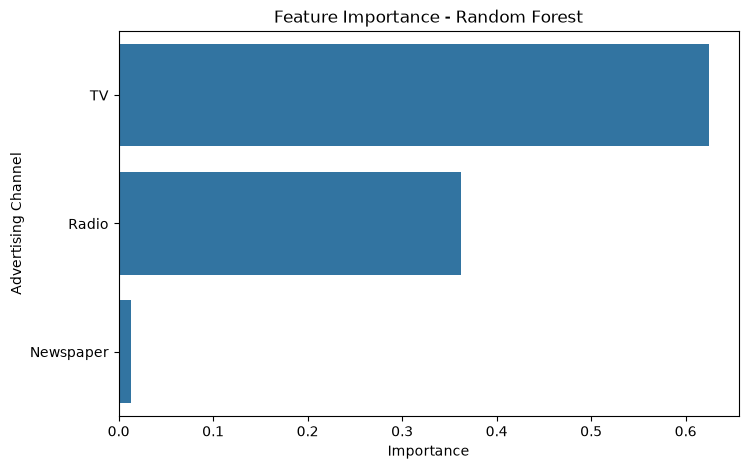

In [27]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Advertising Channel")

plt.show()

## 10. Final Conclusion

In this project, we used the Advertising dataset to predict product Sales from TV, Radio, and Newspaper advertising expenditure.

- We explored the dataset using shape, data types, missing-value checks, descriptive statistics, a pairplot, scatter plots, and a correlation heatmap.
- We trained and compared Linear Regression and Random Forest Regressor.
- On the selected test split, Random Forest achieved MAE = 0.6203, RMSE = 0.7687, and R² = 0.9813, outperforming Linear Regression on these metrics.
- The Random Forest feature-importance results identify TV as the most important predictive feature, followed by Radio and Newspaper.

**Conclusion:** Random Forest is the best-performing model among the two models tested in this project. TV advertising has the highest predictive importance in this fitted model. These findings describe this dataset and evaluation split and should not be interpreted as proof of causation.